# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Manisah Maharani
- **Email:** ds322b6x0961@student.devacademy.id
- **ID Dicoding:** ds322b6x0961

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

##### Dataset Bike Sharing yang digunakan dalam proyek ini merupakan kumpulan main data dari sistem Capital Bikeshare, Washington D.C., AS tahun 2011-2012.

##### Berisi data day dan hour, serta pelanggan dikelompokkan menjadi 2 kategori. Yaitu, kategori casual (non-berlangganan) dan pelanggan registered (terdaftar/berlangganan).

#### Dua pertanyaan bisnis berikut disusun mengikuti metode SMART menggunakan data harian dan jam bike sharing.

- **Pertanyaan 1:** "Bagaimana pola tren jumlah rata-rata penyewaan sepeda per jam pada hari kerja (workingday = 1) dibandingkan hari libur sepanjang tahun 2012 untuk menentukan peak hours operasional?"

- **Pertanyaan 2:** "Bagaimana perbedaan proporsi peminjaman antara pengguna casual dan registered berdasarkan kondisi cuaca (weathersit) selama periode 2011–2012?"

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

Dataset memiliki dua file: `day.csv` (agregasi harian) dan `hour.csv` (agregasi per jam).

Pertanyaan pertama  menganalisis tren penyewaan sepeda per-jam yang akan menggunakan data hour. Sedangkan, pertanyaan kedua menganalisis proporsi pelanggan selama 2 tahun sehingga akan dijawab dengan data harian.

#### Load df Day

In [2]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

print("day_df  :", day_df.shape)
day_df.head()

day_df  : (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:**
- Dataset `day.csv` berisi 731 baris data harian penyewaan sepeda dari 1 Januari 2011 hingga 31 Desember 2012.
- Kolom utama: `dteday`, `season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, `weathersit`, `temp`, `atemp`, `hum`, `windspeed`, `casual`, `registered`, `cnt`.
- `cnt` = count of total rental bikes including both `casual` + `registered`.

#### Load df Hour

In [3]:
print("hour_df :", hour_df.shape)
hour_df.head()

hour_df : (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Dataset `hour.csv` berisi 17.379 baris data per jam penyewaan sepeda.
- Memiliki kolom tambahan `hr` (jam 0–23) dibandingkan `day.csv`.

### Assessing Data

In [4]:
day_df.info()
hour_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Colum

#### Identifying Day and Hour Dataset problem

In [5]:
# Cek missing value kedua dataset
print("\nMissing value day_df :", day_df.isna().sum().sum())
print("Missing value hour_df:", hour_df.isna().sum().sum())

#Cek duplikasi data kedua dataset
print("Duplikat day_df      :", day_df.duplicated().sum())
print("Duplikat hour_df     :", hour_df.duplicated().sum())


Missing value day_df : 0
Missing value hour_df: 0
Duplikat day_df      : 0
Duplikat hour_df     : 0


### Masalah 1: Tipe data tanggal salah

In [6]:
print("Tipe data dteday:", day_df["dteday"].dtype)
print("Contoh nilai    :", day_df["dteday"].iloc[0])

Tipe data dteday: str
Contoh nilai    : 2011-01-01


### Masalah 2: Invalid value pada variabel kelembapan (hum=0)

In [7]:
#Cek invalid dan inaccurate value kedua dataset
print("Jumlah hum = 0 pada day_df:", (day_df['hum'] == 0).sum())
print("Jumlah hum = 0 pada hour_df:", (hour_df['hum'] == 0).sum())

print("\nJumlah windspeed = 0 pada day_df:", (day_df['windspeed'] == 0).sum())
print("Jumlah windspeed = 0 pada hour_df:", (hour_df['windspeed'] == 0).sum())

Jumlah hum = 0 pada day_df: 1
Jumlah hum = 0 pada hour_df: 22

Jumlah windspeed = 0 pada day_df: 0
Jumlah windspeed = 0 pada hour_df: 2180


### Masalah 3: Nilai pada fitur kategorikal masih berupa kode

In [8]:
# Cek fitur kategorikal
print(day_df[["season", "workingday", "weekday", "weathersit"]].apply(lambda s: sorted(s.unique())))
print()
print(day_df[["temp", "atemp", "hum", "windspeed"]].describe().loc[["min", "max"]])
print()
print(hour_df[["season", "workingday", "weekday", "weathersit"]].apply(lambda s: sorted(s.unique())))
print()
print(hour_df[["temp", "atemp", "hum", "windspeed"]].describe().loc[["min", "max"]])

season                 [1, 2, 3, 4]
workingday                   [0, 1]
weekday       [0, 1, 2, 3, 4, 5, 6]
weathersit                [1, 2, 3]
dtype: object

         temp     atemp     hum  windspeed
min  0.059130  0.079070  0.0000   0.022392
max  0.861667  0.840896  0.9725   0.507463

season                 [1, 2, 3, 4]
workingday                   [0, 1]
weekday       [0, 1, 2, 3, 4, 5, 6]
weathersit             [1, 2, 3, 4]
dtype: object

     temp  atemp  hum  windspeed
min  0.02    0.0  0.0     0.0000
max  1.00    1.0  1.0     0.8507


### Masalah 4: Outlier pada fitur `casual`, `windspeed`, dan `hum`

In [9]:
# Cek outlier pada semua fitur numerik
def count_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

for col in ["temp", "atemp", "hum", "windspeed", "casual", "registered", "cnt"]:
    print(f"{col:11s}: {count_outliers(day_df[col])} outlier (IQR)")

temp       : 0 outlier (IQR)
atemp      : 0 outlier (IQR)
hum        : 2 outlier (IQR)
windspeed  : 13 outlier (IQR)
casual     : 44 outlier (IQR)
registered : 0 outlier (IQR)
cnt        : 0 outlier (IQR)


Identifying outlier pada kolom windspeed, humidity, dan cnt problem

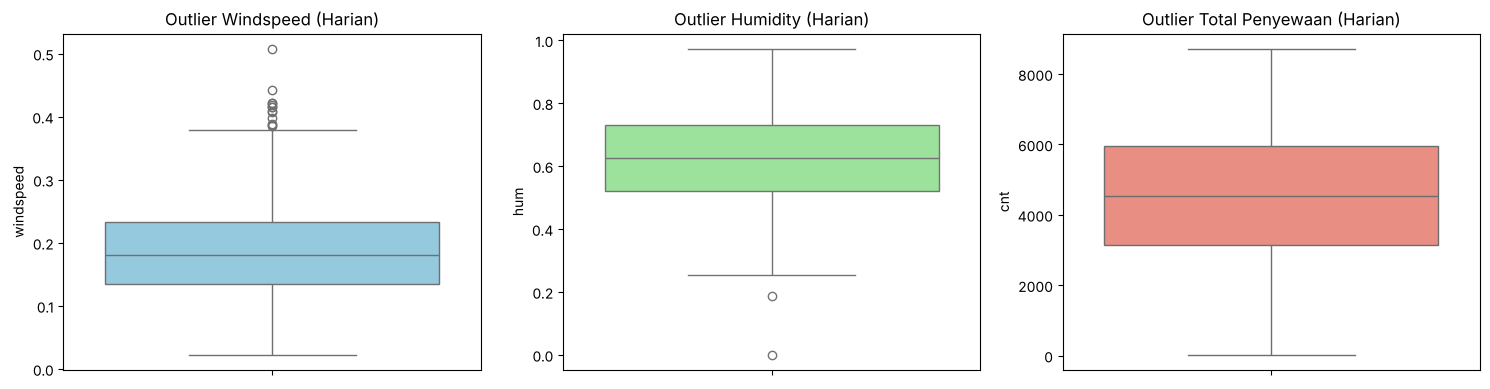

In [10]:
# Cek outlier pada fitur numerik menggunakan boxplot
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(ax=axes[0], y=day_df['windspeed'], color='skyblue')
axes[0].set_title('Outlier Windspeed (Harian)')

sns.boxplot(ax=axes[1], y=day_df['hum'], color='lightgreen')
axes[1].set_title('Outlier Humidity (Harian)')

sns.boxplot(ax=axes[2], y=day_df['cnt'], color='salmon')
axes[2].set_title('Outlier Total Penyewaan (Harian)')

plt.tight_layout()
plt.show()

### Masalah 5: Label musim tidak sesuai tanggal (inaccurate value)

Dokumentasi dataset menyebut `season` 1 = springer, tetapi baris pertama data adalah 1 Januari 2011 dengan `season` = 1. Hal ini dicek dengan melihat bulan apa saja yang masuk ke tiap kode musim.

In [11]:
# Sebaran bulan (kolom) pada tiap kode season (baris)
pd.crosstab(day_df['season'], day_df['mnth'])

mnth,1,2,3,4,5,6,7,8,9,10,11,12
season,,,,,,,,,,,,
1,62,57,40,0,0,0,0,0,0,0,0,22
2,0,0,22,60,62,40,0,0,0,0,0,0
3,0,0,0,0,0,20,62,62,44,0,0,0
4,0,0,0,0,0,0,0,0,16,62,60,40


**Steps to Take:**
- Konversi kolom `dteday` yang masih bertipe object ke tipe datetime.
- Nilai kolom kategorikal `season` di relabeling berdasarkan bulan sebenarnya (bukan dokumentasi): 1 = Dingin, 2 = Semi, 3 = Panas, 4 = Gugur.
- Nilai kolom kategorikal `weathersit` di relabeling menjadi: 1 = Cerah, 2 = Berkabut, 3 = Hujan/Salju, 4 = Hujan/Salju Lebat.
- Nilai kolom kategorikal `weekday` di relabeling menjadi: 0 = Minggu, 1 = Senin, 2 = Selasa, 3 = Rabu, 4 = Kamis, 5 = Jumat, 6 = Sabtu.
- Nilai kolom kategorikal `workingday` di relabeling menjadi: 1 = Hari Kerja, 0 = Libur.
- `Windspeed` memiliki nilai maksimum 0.85 (85 km/jam) yang cukup ekstrem untuk bersepeda. Namun, karena ini data cuaca nyata (bukan kesalahan input), **outlier ini tidak perlu dihapus**.
- `Hum (Kelembapan)` memiliki nilai minimum 0 (0%) yang tidak realistis untuk cuaca sehari-hari. Sehingga,  diubah nilai `0` menjadi `NaN` agar tidak merusak analisis korelasi. Perlakuan ini berlaku untuk `day_df` (1 baris) dan `hour_df` (22 baris).
- `Cnt (Jumlah Penyewaan)` memiliki nilai maksimum yang sangat tinggi (>8000) kemungkinan besar terjadi pada hari libur atau event khusus. Sehingga, **tidak perlu dihapus**, tapi akan dianalisis lebih lanjut di tahap EDA.

- Tidak ditemukan missing value maupun duplikasi data pada dataset.

**Insight:**
- Deteksi outlier visual menggunakan boxplot.
- Outlier pada dataset ini bukanlah "data kotor" yang harus dibuang, melainkan representasi dari kejadian nyata (cuaca ekstrem atau hari libur sibuk).
- Oleh karena itu, dilakukan  *cleaning* yang berfokus pada penanganan nilai *inaccurate* (seperti `hum=0`) dan tidak menghapus data outlier.

### Cleaning Data

#### Fixing tipe data, mapping kategori, dan penanganan inaccurate value problem

In [12]:
# 1. Konversi dteday ke datetime
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

print("=== Tipe data dteday setelah cleaning ===")
print("day_df :", day_df['dteday'].dtype)
print("hour_df:", hour_df['dteday'].dtype)

=== Tipe data dteday setelah cleaning ===
day_df : datetime64[us]
hour_df: datetime64[us]


In [13]:
# 2. Mapping kolom kategorik agar mudah dibaca
# Urutan musim mengikuti bulan sebenarnya (lihat Masalah 5)
season_map = {1: 'Dingin', 2: 'Semi', 3: 'Panas', 4: 'Gugur'}
weather_map = {
    1: 'Cerah',
    2: 'Berkabut',
    3: 'Hujan/Salju',
    4: 'Hujan/Salju Lebat'
}
weekday_map = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu',
               4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}
day_type_map = {0: 'Hari Libur / Akhir Pekan', 1: 'Hari Kerja'}
year_map = {0: 2011, 1: 2012}

# 3. Mapping day_df and hour_df
for df in [day_df, hour_df]:
    df['season_label'] = df['season'].map(season_map)
    df['weather_label'] = df['weathersit'].map(weather_map)
    df['weekday_label'] = df['weekday'].map(weekday_map)
    df['day_type'] = df['workingday'].map(day_type_map)
    df['tahun'] = df['yr'].map(year_map)

print("Setelah cleaning:")
display(day_df[['dteday', 'season_label', 'weather_label', 'weekday_label', 'day_type', 'hum', 'cnt']].head())

Setelah cleaning:


,dteday,season_label,weather_label,weekday_label,day_type,hum,cnt
0,2011-01-01,Dingin,Berkabut,Sabtu,Hari Libur / Akhir Pekan,0.805833,985
1,2011-01-02,Dingin,Berkabut,Minggu,Hari Libur / Akhir Pekan,0.696087,801
2,2011-01-03,Dingin,Cerah,Senin,Hari Kerja,0.437273,1349
3,2011-01-04,Dingin,Cerah,Selasa,Hari Kerja,0.590435,1562
4,2011-01-05,Dingin,Cerah,Rabu,Hari Kerja,0.436957,1600


In [14]:
# 4. Memperbaiki nilai kelembapan `hum` yang invalid (day_df dan hour_df)
for df in [day_df, hour_df]:
    df["hum"] = df["hum"].replace(0, np.nan)
    df["hum"] = df["hum"].interpolate(method="linear")

print("day_df  -> hum = 0 atau NaN tersisa:", day_df["hum"].isna().sum() + (day_df["hum"] == 0).sum())
print("hour_df -> hum = 0 atau NaN tersisa:", hour_df["hum"].isna().sum() + (hour_df["hum"] == 0).sum())
day_df.loc[day_df["dteday"].between("2011-03-09", "2011-03-11"), ["dteday", "hum"]]

day_df  -> hum = 0 atau NaN tersisa: 0
hour_df -> hum = 0 atau NaN tersisa: 0


,dteday,hum
67,2011-03-09,0.775417
68,2011-03-10,0.712491
69,2011-03-11,0.649565


**Insight:**
- **Tipe Data:** Kolom `dteday` berhasil diubah menjadi tipe *datetime* sehingga memudahkan ekstraksi waktu (tahun, bulan, hari) di tahap EDA.
- **Mapping Kategori:** Kolom kode (`season`, `weathersit`, `weekday`, `workingday`, `yr`) kini punya label teks. Label musim memakai urutan berdasarkan bulan sebenarnya: Dingin, Semi, Panas, Gugur (kode 1 mencakup Desember sampai Maret, jadi bukan "springer" seperti di dokumentasi).
- **Inaccurate Value:** Kelembapan 0% (`hum = 0`) diganti hasil interpolasi linear. Pada `day_df`, nilai 10 Maret 2011 menjadi sekitar 71,2% (dari 77,5% dan 65,0% pada hari sebelum dan sesudahnya). `hour_df` ikut dibersihkan dengan cara yang sama (22 baris).

## Exploratory Data Analysis (EDA)

### Explore Pertanyaan 1: Tren Rata-rata per Jam (2012)

In [15]:
# 1. Filter data tahun 2012 (year = 1) menggunakan hour_df
df_2012 = hour_df[hour_df['yr'] == 1]

# 2.  Mengelompokkan berdasarkan 'workingday' dan 'hour'
# Rata-rata penyewaan
hourly_rentals_2012 = df_2012.groupby(by=['workingday', 'hr']).agg({
    'cnt': 'mean'
}).reset_index()

# 3.  Mengubah angka workingday jadi label teks
hourly_rentals_2012['day_type'] = hourly_rentals_2012['workingday'].map({
    0: 'Hari Libur / Akhir Pekan',
    1: 'Hari Kerja'
})

print("Hasil Grup Data Rerata Penyewaan per Jam (2012)")
display(hourly_rentals_2012.head())

Hasil Grup Data Rerata Penyewaan per Jam (2012)


,workingday,hr,cnt,day_type
0,0,0,108.508621,Hari Libur / Akhir Pekan
1,0,1,84.525862,Hari Libur / Akhir Pekan
2,0,2,63.113043,Hari Libur / Akhir Pekan
3,0,3,29.912281,Hari Libur / Akhir Pekan
4,0,4,9.852174,Hari Libur / Akhir Pekan


In [16]:
# Jumlah hari tiap tipe hari pada 2012, dan 3 jam dengan rata-rata penyewaan tertinggi
print("Jumlah hari 2012:")
print(df_2012.groupby('day_type')['dteday'].nunique())

top_hours = (hourly_rentals_2012
             .sort_values(['day_type', 'cnt'], ascending=[True, False])
             .groupby('day_type')
             .head(3))
print("\n3 jam tersibuk per tipe hari:")
display(top_hours[['day_type', 'hr', 'cnt']].round(1))

Jumlah hari 2012:
day_type
Hari Kerja                  250
Hari Libur / Akhir Pekan    116
Name: dteday, dtype: int64

3 jam tersibuk per tipe hari:


,day_type,hr,cnt
41,Hari Kerja,17,656.2
42,Hari Kerja,18,617.0
32,Hari Kerja,8,604.5
13,Hari Libur / Akhir Pekan,13,458.9
12,Hari Libur / Akhir Pekan,12,451.0
14,Hari Libur / Akhir Pekan,14,447.9


**Insight:**
- Sepanjang 2012 terdapat 250 hari kerja dan 116 hari libur/akhir pekan.
- **Hari kerja** punya dua puncak komuter: sore pukul 17:00 (sekitar 656 sepeda/jam) dan 18:00 (sekitar 617), serta pagi pukul 08:00 (sekitar 605). Di antara puncak (10:00-15:00) permintaan turun ke kisaran 170-260 sepeda/jam.
- **Hari libur/akhir pekan** hanya punya satu puncak lebar pada siang hingga sore, tertinggi pukul 13:00 (sekitar 459), diikuti 12:00 dan 14:00. Pukul 08:00 hanya sekitar 135 sepeda/jam.
- Rata-rata penyewaan per jam kedua tipe hari relatif dekat (241 pada hari kerja, 221 pada hari libur), jadi perbedaan utamanya ada pada **jam sibuknya**, bukan volume.

### Explore Pertanyaan 2: Proporsi Pengguna Berdasarkan Cuaca

In [17]:
# 1. Mengelompokkan day_df berdasarkan kondisi cuaca
# Total tiap tipe pengguna
weather_prop = day_df.groupby(by='weathersit').agg({
    'casual': 'sum',
    'registered': 'sum'
}).reset_index()

# 2. Transformasi data
weather_prop_melted = weather_prop.melt(
    id_vars='weathersit',
    value_vars=['casual', 'registered'],
    var_name='user_type',
    value_name='total_users'
)

print("\nHasil Grup Proporsi Pengguna berdasarkan Cuaca")
display(weather_prop_melted.head())


Hasil Grup Proporsi Pengguna berdasarkan Cuaca


,weathersit,user_type,total_users
0,1,casual,446346
1,2,casual,169776
2,3,casual,3895
3,1,registered,1811606
4,2,registered,827082


In [18]:
# 3. Ringkasan per kondisi cuaca: jumlah hari, total, rata-rata harian, dan proporsi pengguna
weather_order = ['Cerah', 'Berkabut', 'Hujan/Salju']

weather_summary = day_df.groupby('weather_label').agg(
    jumlah_hari=('cnt', 'size'),
    total_casual=('casual', 'sum'),
    total_registered=('registered', 'sum'),
    rata2_casual=('casual', 'mean'),
    rata2_registered=('registered', 'mean')
).loc[weather_order]

total_pengguna = weather_summary['total_casual'] + weather_summary['total_registered']
weather_summary['persen_casual'] = weather_summary['total_casual'] / total_pengguna * 100
weather_summary['persen_registered'] = 100 - weather_summary['persen_casual']

print("Persentase casual keseluruhan: {:.1f}%".format(day_df['casual'].sum() / day_df['cnt'].sum() * 100))
display(weather_summary.round(1))

Persentase casual keseluruhan: 18.8%


,jumlah_hari,total_casual,total_registered,rata2_casual,rata2_registered,persen_casual,persen_registered
weather_label,,,,,,,
Cerah,463,446346,1811606,964.0,3912.8,19.8,80.2
Berkabut,247,169776,827082,687.4,3348.5,17.0,83.0
Hujan/Salju,21,3895,33974,185.5,1617.8,10.3,89.7


**Insight:**
- Proporsi pengguna casual paling tinggi saat cuaca **Cerah** (19,8%), turun saat **Berkabut** (17,0%), dan paling rendah saat **Hujan/Salju** (10,3%). Secara keseluruhan casual 18,8% dari total.
- Pengguna registered mendominasi di semua cuaca (80,2% sampai 89,7%), dan porsinya makin besar saat cuaca memburuk.
- Rata-rata casual per hari turun dari 964 (Cerah) menjadi 687 (Berkabut) dan 185 (Hujan/Salju). Registered turun lebih landai: 3.913, 3.349, dan 1.618.
- Catatan: kategori Hujan/Salju hanya berisi 21 hari (Cerah 463 hari, Berkabut 247 hari), sehingga angkanya perlu dibaca hati-hati.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

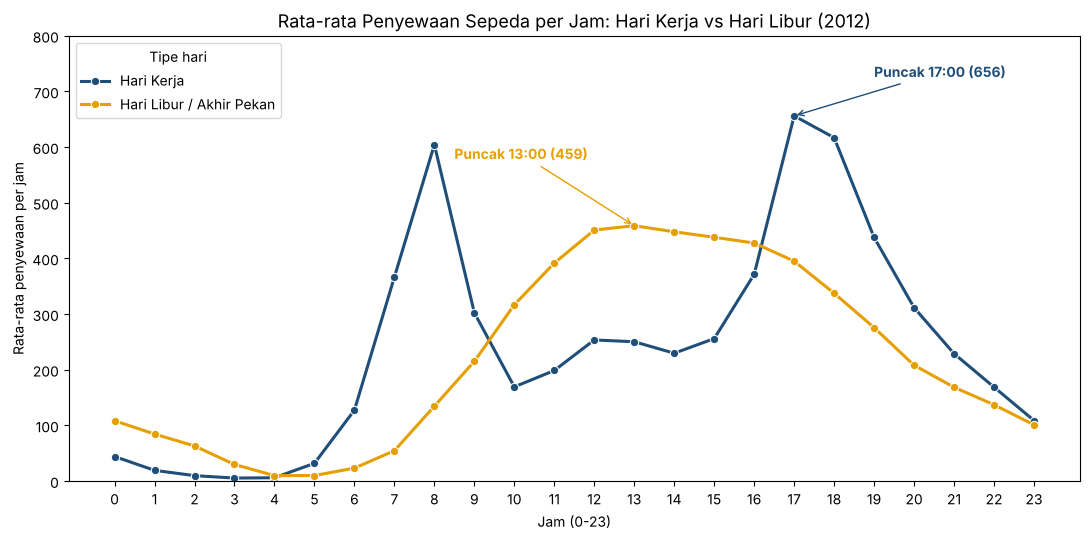

In [19]:
palette_day = {'Hari Kerja': '#1f4e79', 'Hari Libur / Akhir Pekan': '#e69f00'}
label_offset = {'Hari Kerja': (2.0, 70), 'Hari Libur / Akhir Pekan': (-4.5, 120)}

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.lineplot(data=hourly_rentals_2012, x='hr', y='cnt', hue='day_type',
             hue_order=list(palette_day), palette=palette_day,
             marker='o', linewidth=2.2, ax=ax)

# Tandai jam puncak tiap tipe hari
for tipe, grp in hourly_rentals_2012.groupby('day_type'):
    puncak = grp.loc[grp['cnt'].idxmax()]
    dx, dy = label_offset[tipe]
    ax.annotate(f"Puncak {int(puncak['hr']):02d}:00 ({puncak['cnt']:.0f})",
                xy=(puncak['hr'], puncak['cnt']),
                xytext=(puncak['hr'] + dx, puncak['cnt'] + dy),
                arrowprops=dict(arrowstyle='->', color=palette_day[tipe]),
                color=palette_day[tipe], fontweight='bold')

ax.set_title('Rata-rata Penyewaan Sepeda per Jam: Hari Kerja vs Hari Libur (2012)', fontsize=13)
ax.set_xlabel('Jam (0-23)')
ax.set_ylabel('Rata-rata penyewaan per jam')
ax.set_xticks(range(24))
ax.set_ylim(0, 800)
ax.legend(title='Tipe hari')
plt.tight_layout()
plt.show()

### Pertanyaan 2:

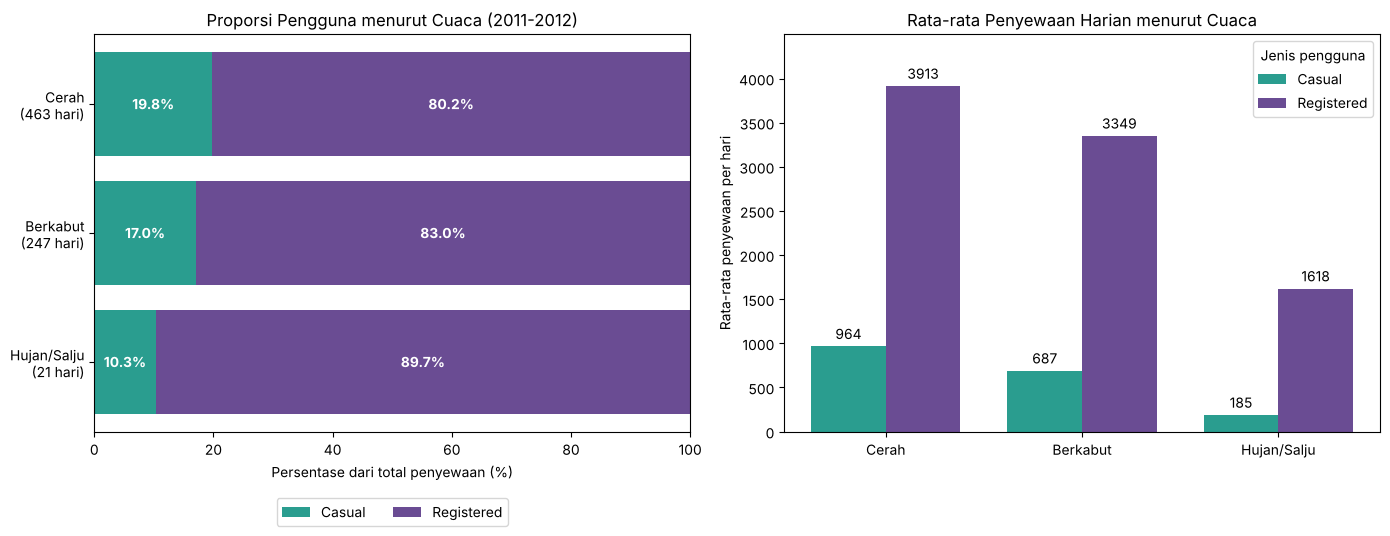

In [20]:
palette_user = {'casual': '#2a9d8f', 'registered': '#6a4c93'}
ytick_labels = [f"{w}\n({int(n)} hari)" for w, n in zip(weather_summary.index, weather_summary['jumlah_hari'])]

fig, (ax_prop, ax_avg) = plt.subplots(1, 2, figsize=(14, 5.5))

# Panel kiri: proporsi casual vs registered (100%)
ax_prop.barh(ytick_labels, weather_summary['persen_casual'],
             color=palette_user['casual'], label='Casual')
ax_prop.barh(ytick_labels, weather_summary['persen_registered'],
             left=weather_summary['persen_casual'],
             color=palette_user['registered'], label='Registered')
for i, (pc, pr) in enumerate(zip(weather_summary['persen_casual'], weather_summary['persen_registered'])):
    ax_prop.text(pc / 2, i, f"{pc:.1f}%", ha='center', va='center', color='white', fontweight='bold')
    ax_prop.text(pc + pr / 2, i, f"{pr:.1f}%", ha='center', va='center', color='white', fontweight='bold')
ax_prop.set_xlim(0, 100)
ax_prop.invert_yaxis()
ax_prop.set_title('Proporsi Pengguna menurut Cuaca (2011-2012)', fontsize=12)
ax_prop.set_xlabel('Persentase dari total penyewaan (%)')
ax_prop.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=2)

# Panel kanan: rata-rata penyewaan harian tiap tipe pengguna
pos = np.arange(len(weather_order))
width = 0.38
bar_c = ax_avg.bar(pos - width / 2, weather_summary['rata2_casual'], width,
                   color=palette_user['casual'], label='Casual')
bar_r = ax_avg.bar(pos + width / 2, weather_summary['rata2_registered'], width,
                   color=palette_user['registered'], label='Registered')
ax_avg.bar_label(bar_c, fmt='%.0f', padding=3)
ax_avg.bar_label(bar_r, fmt='%.0f', padding=3)
ax_avg.set_xticks(pos)
ax_avg.set_xticklabels(weather_order)
ax_avg.set_ylim(0, weather_summary['rata2_registered'].max() * 1.15)
ax_avg.set_title('Rata-rata Penyewaan Harian menurut Cuaca', fontsize=12)
ax_avg.set_ylabel('Rata-rata penyewaan per hari')
ax_avg.legend(title='Jenis pengguna')

plt.tight_layout()
plt.show()

**Insight:**
- **Pertanyaan 1:** pola jam berbeda jelas. Hari kerja didominasi dua puncak komuter (08:00 dan 17:00-18:00), sedangkan hari libur membentuk satu "bukit" lebar yang memuncak sekitar 13:00.
- **Pertanyaan 2:** semakin buruk cuaca, semakin kecil porsi casual (19,8% menjadi 17,0% menjadi 10,3%). Pengguna casual lebih sensitif terhadap cuaca daripada registered.
- Semua grafik batang dimulai dari nol agar tinggi batang bisa dibandingkan secara jujur.

## Analisis Lanjutan (Opsional)

Teknik yang dipakai adalah **manual grouping / binning** (tanpa machine learning): 24 jam dikelompokkan menjadi 5 segmen waktu berdasarkan aturan bisnis, lalu dihitung berapa persen penyewaan harian yang jatuh di tiap segmen (data 2012). Hasilnya melengkapi Pertanyaan 1 karena memberi jendela waktu operasional yang lebih mudah dipakai daripada 24 titik jam.

| Segmen | Jam |
|---|---|
| Dini Hari | 00-05 |
| Pagi | 06-09 |
| Siang | 10-15 |
| Sore | 16-19 |
| Malam | 20-23 |

RFM tidak dipakai karena data tidak memuat identitas pelanggan, dan analisis geospasial tidak dipakai karena data tidak memuat lokasi.

time_slot,Dini Hari (00-05),Pagi (06-09),Siang (10-15),Sore (16-19),Malam (20-23)
day_type,,,,,
Hari Kerja,2.0,24.2,23.5,36.1,14.2
Hari Libur / Akhir Pekan,5.8,8.1,47.4,27.2,11.6


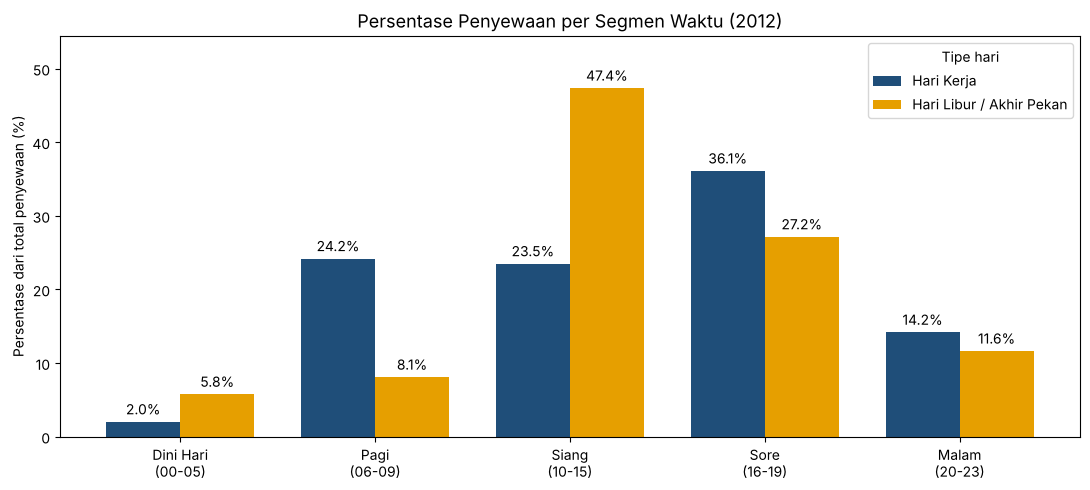

In [21]:
slot_bins = [-1, 5, 9, 15, 19, 23]
slot_labels = ['Dini Hari (00-05)', 'Pagi (06-09)', 'Siang (10-15)', 'Sore (16-19)', 'Malam (20-23)']
hour_df['time_slot'] = pd.cut(hour_df['hr'], bins=slot_bins, labels=slot_labels)

# Persentase penyewaan 2012 yang jatuh di tiap segmen waktu
hour_2012 = hour_df[hour_df['yr'] == 1]
slot_total = hour_2012.groupby(['day_type', 'time_slot'], observed=True)['cnt'].sum().unstack()
slot_share = slot_total.div(slot_total.sum(axis=1), axis=0).mul(100)
slot_share = slot_share.loc[list(palette_day)]
display(slot_share.round(1))

fig, ax = plt.subplots(figsize=(11, 5))
pos = np.arange(len(slot_labels))
width = 0.38
for k, tipe in enumerate(slot_share.index):
    bars = ax.bar(pos + (k - 0.5) * width, slot_share.loc[tipe], width,
                  color=palette_day[tipe], label=tipe)
    ax.bar_label(bars, fmt='%.1f%%', padding=3)
ax.set_xticks(pos)
ax.set_xticklabels([s.replace(' (', '\n(') for s in slot_labels])
ax.set_ylim(0, slot_share.values.max() * 1.15)
ax.set_title('Persentase Penyewaan per Segmen Waktu (2012)', fontsize=13)
ax.set_ylabel('Persentase dari total penyewaan (%)')
ax.legend(title='Tipe hari')
plt.tight_layout()
plt.show()

**Insight:**
- Pada hari kerja, segmen **Sore (16-19)** menyumbang 36,1% penyewaan dan **Pagi (06-09)** 24,2%. Keduanya (4 jam + 4 jam) menampung sekitar 60% penyewaan harian.
- Pada hari libur, segmen **Siang (10-15)** terbesar dengan 47,4%, lalu Sore 27,2%.
- Segmen **Dini Hari (00-05)** paling sepi, terutama pada hari kerja (2,0%), sehingga cocok untuk perawatan dan rebalancing armada.

### Menyimpan data bersih untuk dashboard

In [22]:
os.makedirs("dashboard", exist_ok=True)

main_data = day_df[['dteday', 'tahun', 'season_label', 'weather_label', 'weekday_label',
                    'day_type', 'casual', 'registered', 'cnt']]
hour_data = hour_df[['dteday', 'hr', 'tahun', 'day_type', 'weather_label',
                     'casual', 'registered', 'cnt', 'time_slot']].copy()
hour_data['time_slot'] = hour_data['time_slot'].astype(str)

main_data.to_csv("dashboard/main_data.csv", index=False)
hour_data.to_csv("dashboard/hour_data.csv", index=False)
print("main_data.csv:", main_data.shape, "| hour_data.csv:", hour_data.shape)

main_data.csv: (731, 9) | hour_data.csv: (17379, 9)


## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada 2012, hari kerja punya dua puncak penyewaan: sore pukul 17:00-18:00 (sekitar 656 dan 617 sepeda/jam) dan pagi pukul 08:00 (sekitar 605). Hari libur hanya punya satu puncak lebar pada siang hingga sore, tertinggi pukul 13:00 (sekitar 459). Dalam segmen waktu, Pagi + Sore menampung sekitar 60% penyewaan hari kerja, sedangkan Siang menampung 47,4% penyewaan hari libur. Jadi peak hours bergantung pada tipe hari.
- **Conclusion pertanyaan 2:** Pada 2011-2012, pengguna registered mendominasi di semua kondisi cuaca. Porsi casual turun saat cuaca memburuk: 19,8% (Cerah), 17,0% (Berkabut), dan 10,3% (Hujan/Salju). Rata-rata casual per hari turun dari 964 menjadi 185 saat hujan/salju, sedangkan registered turun dari 3.913 menjadi 1.618, sehingga casual lebih sensitif terhadap cuaca.

**Rekomendasi Action Item:**
- **Hari kerja:** pastikan stok sepeda di stasiun penuh sebelum 07:00 dan 16:00, karena puncaknya pukul 08:00 dan 17:00-18:00. Jadwalkan rebalancing di sela puncak (10:00-15:00).
- **Hari libur/akhir pekan:** siapkan armada penuh pukul 10:00-16:00, dan arahkan promosi paket harian atau wisata pada rentang itu.
- **Perawatan:** gunakan dini hari (00:00-05:00), yang hanya 2,0% penyewaan pada hari kerja, untuk servis dan rebalancing.
- **Cuaca:** pantau prakiraan cuaca. Saat berkabut atau hujan, kurangi armada yang disiagakan untuk pengguna casual (turun sampai sekitar 19% dari hari cerah pada hujan/salju), dan fokus pada pengguna registered. Promo untuk pengguna casual lebih efektif diluncurkan pada hari cerah.
- **Catatan keterbatasan:** hasil menunjukkan pola, bukan sebab-akibat. Kategori Hujan/Salju hanya 21 hari, dan analisis jam hanya memakai tahun 2012.